In [1]:
%load_ext cudf.pandas
import pandas as pd
import numpy as np

from datasets import load_dataset
import warnings
warnings.filterwarnings('ignore')

#### Loading the dataset

In [2]:
data = load_dataset('jxie/flickr8k')

README.md:   0%|          | 0.00/687 [00:00<?, ?B/s]

data/train-00000-of-00002-2f8f6bfa852eac(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00000-of-00002-2f8f6bfa852eac(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-2173151d8cd6c7(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00001-of-00002-2173151d8cd6c7(…): downloading bytes:           |  0.00B            

...

data/test-00000-of-00001-42a2661d12c73e4(…): reconstructing file:   0%|          |  0.00B /  137MB            

data/test-00000-of-00001-42a2661d12c73e4(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/6000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

In [3]:
data.shape

{'train': (6000, 6), 'validation': (1000, 6), 'test': (1000, 6)}

In [4]:
print(data['train'])

Dataset({
    features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
    num_rows: 6000
})


In [5]:
data['train'][0]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=500x399>,
 'caption_0': 'A black dog is running after a white dog in the snow .',
 'caption_1': 'Black dog chasing brown dog through snow',
 'caption_2': 'Two dogs chase each other across the snowy ground .',
 'caption_3': 'Two dogs play together in the snow .',
 'caption_4': 'Two dogs running through a low lying body of water .'}

In [6]:
train = data['train']
test = data['test']
validation = data['validation']

In [7]:
test[0]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=500x335>,
 'caption_0': 'The dogs are in the snow in front of a fence .',
 'caption_1': 'The dogs play on the snow .',
 'caption_2': 'Two brown dogs playfully fight in the snow .',
 'caption_3': 'Two brown dogs wrestle in the snow .',
 'caption_4': 'Two dogs playing in the snow .'}

#### Visualizing the data

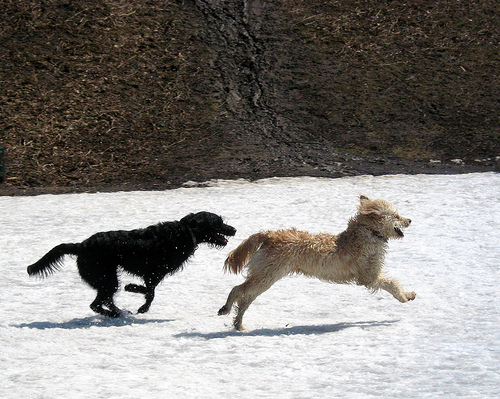

In [8]:
display(train[0]['image'])


================================================== IMG 1 ==================================================
A black dog is running after a white dog in the snow .
Black dog chasing brown dog through snow
Two dogs chase each other across the snowy ground .
Two dogs play together in the snow .
Two dogs running through a low lying body of water .



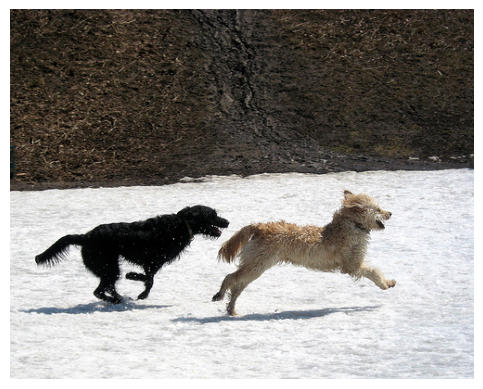


================================================== IMG 2 ==================================================
A little baby plays croquet .
A little girl plays croquet next to a truck .
The child is playing croquette by the truck .
The kid is in front of a car with a put and a ball .
The little boy is playing with a croquet hammer and ball beside the car .



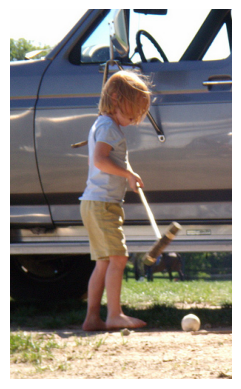


================================================== IMG 3 ==================================================
A brown dog in the snow has something hot pink in its mouth .
A brown dog in the snow holding a pink hat .
A brown dog is holding a pink shirt in the snow .
A dog is carrying something pink in its mouth while walking through the snow .
A dog with something pink in its mouth is looking forward .



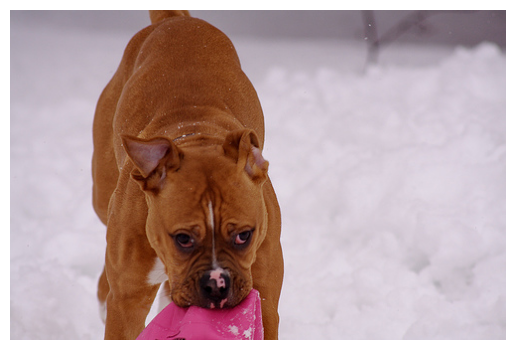


================================================== IMG 4 ==================================================
A brown dog is running along a beach .
A brown dog wearing a black collar running across the beach .
A dog walks on the sand near the water .
Brown dog running on the beach .
The large brown dog is running on the beach by the ocean .



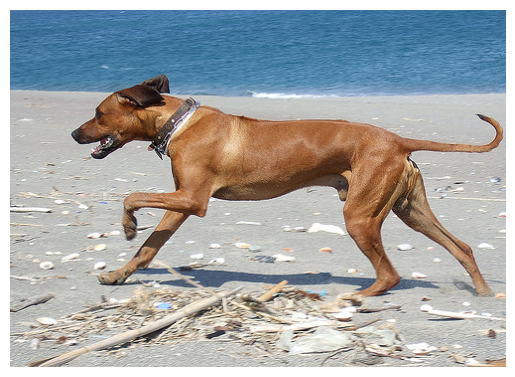


================================================== IMG 5 ==================================================
A black and white dog with a red Frisbee standing on a sandy beach .
A dog drops a red disc on a beach .
A dog with a red Frisbee flying in the air .
Dog catching a red Frisbee .
The black dog is dropping a red disc on a beach .



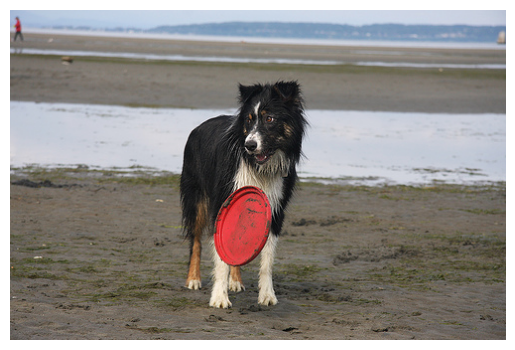

In [9]:
import matplotlib.pyplot as plt

def show(num):
    for i in range(5):
        print(train[num][f'caption_{i}'])

    print()
    plt.imshow(train[num]['image'])
    plt.axis('off')
    plt.show()


for i in range(5):
    print()
    print("=" * 50, f'IMG {i+1}', "=" * 50)
    show(i)

#### Image preprocessing

In [12]:
for split_name in ['train', 'validation', 'test']:
    # Remove 'image' column so it only converts text to a DataFrame
    df = data[split_name].remove_columns('image').to_pandas()
    
    print(f"=== Null values in {split_name} ===")
    print(df.isnull().sum())
    print()

=== Null values in train ===
caption_0    0
caption_1    0
caption_2    0
caption_3    0
caption_4    0
dtype: int64

=== Null values in validation ===
caption_0    0
caption_1    0
caption_2    0
caption_3    0
caption_4    0
dtype: int64

=== Null values in test ===
caption_0    0
caption_1    0
caption_2    0
caption_3    0
caption_4    0
dtype: int64



#### Converting into pandas dataframe

In [16]:
train = pd.DataFrame({
    'image': [item['image'] for item in train],
    'caption_0': train['caption_0'],
    'caption_1': train['caption_1'],
    'caption_2': train['caption_2'],
    'caption_3': train['caption_3'],
    'caption_4': train['caption_4'],
})

test = pd.DataFrame({
    'image': [item['image'] for item in test],
    'caption_0': test['caption_0'],
    'caption_1': test['caption_1'],
    'caption_2': test['caption_2'],
    'caption_3': test['caption_3'],
    'caption_4': test['caption_4'],
})

validation = pd.DataFrame({
    'image': [item['image'] for item in validation],
    'caption_0': validation['caption_0'],
    'caption_1': validation['caption_1'],
    'caption_2': validation['caption_2'],
    'caption_3': validation['caption_3'],
    'caption_4': validation['caption_4'],
})


In [18]:
print(train.shape)
print(test.shape)
print(validation.shape)
print()
train.sample(5)

(6000, 6)
(1000, 6)
(1000, 6)



,image,caption_0,caption_1,caption_2,caption_3,caption_4
1110,<PIL.JpegImagePlugin.JpegImageFile image mode=...,The dogs play in the snow on hind legs .,Two dogs jump on each other in the snow .,Two dogs play and appear to be hugging in the ...,Two dogs playing in snow .,Two dogs wrestle in the snow in a fenced-in ar...
936,<PIL.JpegImagePlugin.JpegImageFile image mode=...,A skier flies through the air .,Ski boot gets pulled out of the ski .,The feet of a skier with one boot coming out o...,Two boots are on two skis moving very fast .,Two feet wearing yellow ski boots on ski
3564,<PIL.JpegImagePlugin.JpegImageFile image mode=...,A dog in a field jumps for a Frisbee .,a small black and white jumping to catch somet...,"A small , white dog with his tongue out is jum...",A white dog is jumping up in the air to catch ...,White dog with dark markings jumping to catch ...
3756,<PIL.JpegImagePlugin.JpegImageFile image mode=...,The girls are playing with foam swords .,Two girls sparring with a red and blue bat whi...,Two kids with helmets playing with Nerf swords...,Two young girls playing with rubber swords in ...,Two young girls with sponge bats being to play...
691,<PIL.JpegImagePlugin.JpegImageFile image mode=...,a lone skateboarder in midair with a huge wood...,A male skateboarder Takes advantage of the hal...,A skateboarder high in the air at indoor ramp .,"Man on skateboard , jumping through the air .",Skateboarder performing a trick high in the ai...


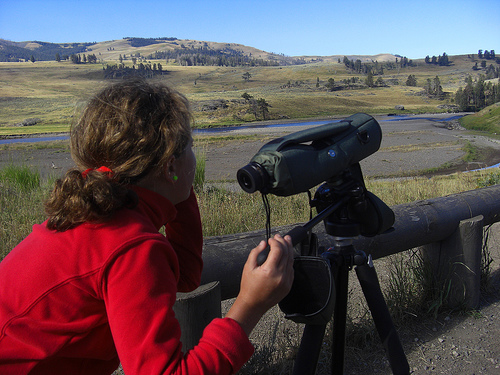

A photographer looks over the hills .
A woman in a red jacket is videotaping a natural landscape .
A woman with a camera looks out over rolling hills .
A woman with a camera on a tripod is looking at the view .
Lady in red shirt has her camera set up in the field to record something .


In [23]:
display(train['image'][10])
print(train['caption_0'][10])
print(train['caption_1'][10])
print(train['caption_2'][10])
print(train['caption_3'][10])
print(train['caption_4'][10])

#### Image preprocessing

In [26]:
# importing tensorflow

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential

In [34]:

# preprocessing the image
img_augmentation = keras.Sequential([
    layers.Resizing(224, 224),                              # taking img as 224 x 224 input size, as considered good universally in computer vision
    layers.Rescaling(1.0 / 225.0),                          # scaling the pixels btwn 0 and 1
    layers.RandomFlip('horizontal'),                        # keep in mind, only flip imgs horizontally, not vertically    
])


# converting PIL img into a preprocessed tensor
def preprocess_img(img, augment=False):
    rgb_img = img.convert('RGB')                             # converting imgs into rgb
    img = keras.preprocessing.image.img_to_array(img)        # converting rgb img into tensor
    img = tf.image.resize(img, (224,224))                     # resizing the img
    img = img / 255.0                                        # rescaling the img

    if augment:
        img_tensor = tf.image.random_flip_left_right(img)

    return img

Original Image size:     (500, 399) (Width, Height)
Preprocessed Tensor shape: (224, 224, 3) (Height, Width, Channels)
Min pixel value:         0.0
Max pixel value:         1.0


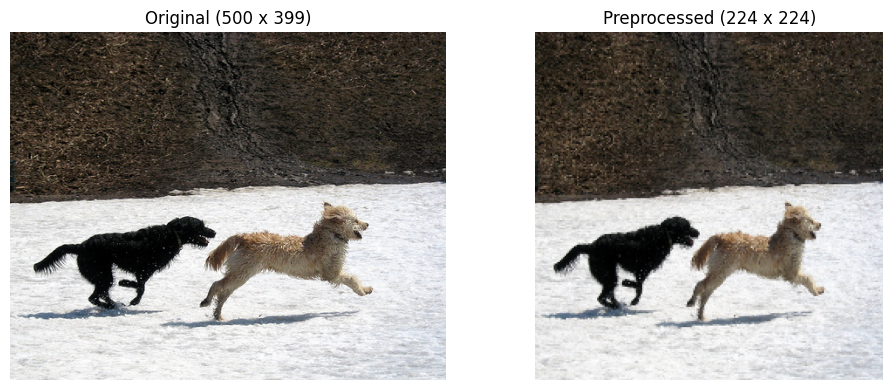

In [35]:
# CHECKING IMAGE BEFORE AND AFTER PREPROCESSING

# Use data['train'] directly:
temp = data['train'][0]['image']

temp_tensor = preprocess_img(temp)

print("Original Image size:    ", temp.size, "(Width, Height)")
print("Preprocessed Tensor shape:", temp_tensor.shape, "(Height, Width, Channels)")
print("Min pixel value:        ", float(tf.reduce_min(temp_tensor)))
print("Max pixel value:        ", float(tf.reduce_max(temp_tensor)))

# Plot
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(temp)
plt.title(f"Original ({temp.size[0]} x {temp.size[1]})")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(temp_tensor.numpy())
plt.title(f"Preprocessed ({temp_tensor.shape[0]} x {temp_tensor.shape[1]})")
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# def load_and_preprocess_image(pil_img):
#     return preprocess_image(pil_img)

# # Quick demonstration of applying it to a batch
# sample_batch_images = [train[i]['image'] for i in range(4)]
# batch_tensor = tf.stack([preprocess_image(img) for img in sample_batch_images])

# print("Batch shape ready for model input:", batch_tensor.shape) 
# # Output: (4, 224, 224, 3)